# CIFAR-10 ResNet: reproducible training

Competition: https://www.kaggle.com/competitions/cifar-10-res-net-architecture-challenge-dl/overview

This notebook bundles this project's Python source, **not data, credentials, or weights**. It can run in Kaggle, Colab or a local checkout. Keep it private while preparing competition work, in accordance with the sharing rules. Attach the authorized competition data or set `CIFAR10_DATA_ROOT`.

**Modes:** `inspect` only checks the model/data; `smoke` checks a small pipeline on CPU; `pilot` runs up to 5 epochs on CUDA; `full` runs the saved 120-epoch schedule. The default is `inspect`. Choose the mode deliberately. Smoke results are not competition results. Existing PyTorch/CUDA installations are preserved.

Rules: residual CNN, at most 5,000,000 trainable parameters, train from scratch, authorized CIFAR-10 training data only; no external weights/data. Report deadline and requirements are in the repository's course checklist.

In [1]:
# Reconstruct the exact bundled source in a fresh temporary workspace.
import base64, hashlib, io, json, os, sys, tempfile, zipfile
from pathlib import Path
SOURCE_BUNDLE = '...'
raw = base64.b64decode(SOURCE_BUNDLE)
assert hashlib.sha256(raw).hexdigest() == '5397e671f18a36546cd9eb18a919d4a304890d2a22e0bc2b8840f9bafe9483cc'
PROJECT_ROOT = Path(tempfile.mkdtemp(prefix="cifar-resnet-"))
with zipfile.ZipFile(io.BytesIO(raw)) as bundle:
    assert all(not Path(n).is_absolute() and ".." not in Path(n).parts for n in bundle.namelist())
    bundle.extractall(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))
print("Source bundle SHA256:", hashlib.sha256(raw).hexdigest())


Source bundle SHA256: 5397e671f18a36546cd9eb18a919d4a304890d2a22e0bc2b8840f9bafe9483cc


In [2]:
import torch
from cifar_project.model import CifarResNet

# Edit these values for your runtime, or supply the corresponding environment variables.
RUN_MODE = os.environ.get("CIFAR_RUN_MODE", "inspect")
if RUN_MODE not in {"inspect", "smoke", "pilot", "full"}:
    raise ValueError("Unknown RUN_MODE")
data_setting = os.environ.get("CIFAR10_DATA_ROOT")
if data_setting:
    DATA_ROOT = Path(data_setting)
elif Path("/kaggle/input").is_dir():
    candidates = [p.parent for p in Path("/kaggle/input").rglob("train_labels.csv")
                  if (p.parent / "train_images").is_dir()]
    if len(candidates) != 1:
        raise RuntimeError("Attach the competition data or explicitly set CIFAR10_DATA_ROOT")
    DATA_ROOT = candidates[0]
else:
    DATA_ROOT = Path("data/competition")  # Edit for Colab/local storage.
OUTPUT_ROOT = Path(os.environ.get("CIFAR_OUTPUT_DIR", "outputs/baseline-seed42"))
config = json.loads((PROJECT_ROOT / "configs/baseline.json").read_text())
model = CifarResNet(config["base_width"], config["blocks_per_stage"])
print("Run mode:", RUN_MODE)
print("PyTorch:", torch.__version__, "CUDA available:", torch.cuda.is_available())
print("Trainable parameters:", model.parameter_count)
if RUN_MODE in {"pilot", "full"} and not torch.cuda.is_available():
    raise RuntimeError("This training mode requires a GPU runtime; CPU smoke mode is available separately")
if RUN_MODE == "smoke":
    print("SMOKE CHECK ONLY: this is not a full training run or a leaderboard result")


Run mode: smoke
PyTorch: 2.9.0+cpu CUDA available: False
Trainable parameters: 1084586
SMOKE CHECK ONLY: this is not a full training run or a leaderboard result


In [3]:
from cifar_project.data import CsvImages, research_split
dataset = CsvImages(DATA_ROOT / "train_labels.csv", DATA_ROOT / "train_images")
split = research_split(dataset.labels, config["validation_fraction"], config["confirmation_fraction"], config["split_seed"])
training, validation, confirmation = [split[key] for key in ["training", "validation", "confirmation"]]
assert not set(training) & set(validation) and not set(training) & set(confirmation) and not set(validation) & set(confirmation)
print("Authorized training rows:", len(dataset))
print("Training/development/untouched confirmation:", len(training), len(validation), len(confirmation))
print("Input shape:", tuple(dataset[0][0].shape))


Authorized training rows: 60
Training/development/untouched confirmation: 40 10 10
Input shape: (3, 32, 32)


In [4]:
from cifar_project.train import main as train_main
if RUN_MODE != "inspect":
    arguments = ["--config", str(PROJECT_ROOT / "configs/baseline.json"),
                 "--data-root", str(DATA_ROOT), "--train-csv", "train_labels.csv",
                 "--output-dir", str(OUTPUT_ROOT),
                 "--device", "cpu" if RUN_MODE == "smoke" else "cuda"]
    if RUN_MODE == "smoke":
        arguments += ["--stop-after-epoch", "1", "--limit-train-batches", "1",
                      "--limit-val-batches", "1", "--smoke-test"]
    elif RUN_MODE == "pilot":
        arguments += ["--stop-after-epoch", "5"]
    if (OUTPUT_ROOT / "last.pt").is_file():
        arguments += ["--resume", str(OUTPUT_ROOT / "last.pt")]
    summary = train_main(arguments)
else:
    print("Inspection complete; no training started.")


{"epoch": 1, "learning_rate": 0.02, "train": {"loss": 2.3878164291381836, "accuracy": 0.1, "examples": 40}, "validation": {"loss": 2.346144199371338, "accuracy": 0.1, "examples": 10}, "seconds": 0.5470297739999523}


{
  "completed_epochs": 1,
  "planned_epochs": 120,
  "best_epoch": 1,
  "validation_accuracy": 0.1,
  "trainable_parameters": 1084586,
  "smoke_test": true,
  "official_test_accuracy": null,
  "note": "Hidden test accuracy is only known after an authorized Kaggle submission."
}


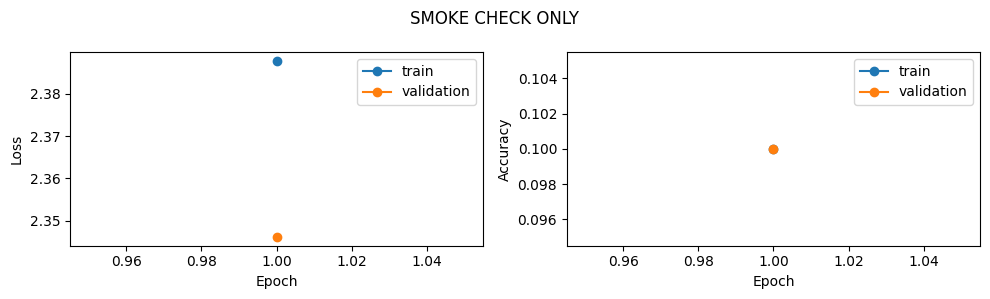

Best validation accuracy: 0.1
Trainable parameters: 1084586
Official hidden test accuracy: None


In [5]:
import matplotlib.pyplot as plt
if RUN_MODE != "inspect":
    metrics = [json.loads(line) for line in (OUTPUT_ROOT / "metrics.jsonl").read_text().splitlines()]
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    for key in ["train", "validation"]:
        axes[0].plot([m["epoch"] for m in metrics], [m[key]["loss"] for m in metrics], label=key, marker="o")
        axes[1].plot([m["epoch"] for m in metrics], [m[key]["accuracy"] for m in metrics], label=key, marker="o")
    for axis, label in zip(axes, ["Loss", "Accuracy"]):
        axis.set_xlabel("Epoch"); axis.set_ylabel(label); axis.legend()
    fig.suptitle("SMOKE CHECK ONLY" if RUN_MODE == "smoke" else "Fixed holdout training curves")
    fig.tight_layout(); fig.savefig(OUTPUT_ROOT / "training-curves.png"); plt.show()
    print("Best validation accuracy:", summary["validation_accuracy"])
    print("Trainable parameters:", summary["trainable_parameters"])
# Fill this only from a confirmed official Kaggle result; never substitute holdout accuracy.
OFFICIAL_KAGGLE_ACCURACY = None
print("Official hidden test accuracy:", OFFICIAL_KAGGLE_ACCURACY)


In [6]:
# Generation is opt-in. This cell never uploads predictions.
GENERATE_SUBMISSION = False
if GENERATE_SUBMISSION:
    from cifar_project.predict import main as predict_main
    args = ["--checkpoint", str(OUTPUT_ROOT / "best.pt"), "--data-root", str(DATA_ROOT),
            "--output", str(OUTPUT_ROOT / "submission.csv"),
            "--device", "cpu" if RUN_MODE == "smoke" else "cuda"]
    if RUN_MODE == "smoke":
        args += ["--allow-smoke-checkpoint"]
    predict_main(args)


## Results and citations

Before final delivery, run the full experiment, preserve the executed notebook, record official Kaggle scores, complete the architecture/ablation comparison, and cite all referenced methods/code. Record the code commit/source hash, configuration, data version, split, seed, GPU and dependencies with the artifacts.

- He et al. *Deep Residual Learning for Image Recognition*. https://arxiv.org/abs/1512.03385
- Course-recommended implementation reference: https://github.com/kuangliu/pytorch-cifar (reference only; pretrained weights are never loaded).
- PyTorch and torchvision: https://pytorch.org/ and https://pytorch.org/vision/

The report is at most 8 pages including figures, tables and citations. Its first page must link to the publicly accessible final repository; coordinate publication with the competition's sharing requirements. Every team member uploads the report PDF to Brightspace.